# Señales sísmicas del CSN: el Data Lake en MinIO

**Consumo 5 · Consultas ad-hoc y exploración.** Este notebook lee las dos zonas del **Data Lake**
on-premise, sin copiar los datos:

- **raw**: cada miniSEED tal como lo entrega el CSN, escrito por NiFi;
- **curated**: los metadatos de cabecera (`cabeceras.parquet`) y el tensor de ventanas de 60 s en
  unidades físicas (`ventanas.zarr`) que deja el curado con ObsPy.

**Preguntas que responde:** ¿qué cubre el data lake?, ¿cómo se lee un lote para entrenar un modelo
de Deep Learning? y ¿cómo luce la señal de un sismo en cada estación?

| Herramienta | Para qué se usa |
| --- | --- |
| **obstore** | Listar los objetos de los buckets de MinIO |
| **DuckDB** (`httpfs`) | SQL directo sobre los Parquet de `s3://curated`, con las particiones de la ruta como columnas |
| **Zarr** | Leer el tensor `[ventana, muestra]` por bloques: solo se descarga lo que se usa |
| **PyIceberg** | Cruzar con el catálogo USGS del Lakehouse para saber qué sismo produjo cada señal |

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import mlab

import conexiones as cx

tensores = cx.tensores()
estaciones = cx.estaciones_csn()
print(f"MinIO del data lake: {cx.DATALAKE_S3} | {len(tensores)} particiones curadas con tensor Zarr")
estaciones

MinIO del data lake: http://minio-datalake:9000 | 6 particiones curadas con tensor Zarr


,sitio,latitud,longitud
estacion,,,
AC01,Pan de Azucar,-26.147880,-70.598660
AP01,Chacalluta,-18.370840,-70.341970
B05O,189 3ra Comisaria Pichilemu,-34.388618,-72.002426
BO01,Tunca,-34.391700,-71.084800
BO02,Daracena,-34.792453,-70.781492
VA05,Santo Domingo,-33.657110,-71.614280


## 1. Zona raw: los miniSEED que dejó NiFi

La ruta de cada objeto es `red / estacion / canal / anio / dia_juliano`, el orden que pide el diseño
para leer en secuencia todo un canal o todo un día.

In [2]:
raw = pd.DataFrame([cx.particion(o["path"]) | {"bytes": o["size"]}
                    for o in cx.objetos("raw") if o["path"].endswith(".mseed")])
print(f"{len(raw)} miniSEED, {raw.bytes.sum() / 2**20:.1f} MB en s3://raw/{cx.FUENTE_CSN}/")
raw.groupby(["estacion", "canal", "anio", "dia_juliano"]).agg(
    archivos=("bytes", "size"), kb=("bytes", lambda b: round(b.sum() / 1024))).reset_index()

108 miniSEED, 4.5 MB en s3://raw/csn_chile/


,estacion,canal,anio,dia_juliano,archivos,kb
0,AC01,HHZ,2026,299,18,536
1,AP01,HHZ,2026,299,18,948
2,B05O,HNZ,2026,299,18,1333
3,BO01,HHZ,2026,299,18,630
4,BO02,HHZ,2026,299,18,683
5,VA05,HNZ,2026,299,18,509


## 2. Cabeceras con DuckDB, directo sobre MinIO

DuckDB lee los `cabeceras.parquet` de todas las particiones con un solo comodín (`**`), y con
`hive_partitioning` convierte las carpetas `anio=` y `dia_juliano=` en columnas. No hay que bajar
los archivos: DuckDB pide a MinIO solo las partes del Parquet que necesita.

In [3]:
db = cx.duckdb_datalake()
cabeceras = "read_parquet('s3://curated/csn_chile/**/cabeceras.parquet', hive_partitioning = true)"
db.sql(f"""
    SELECT estacion, canal, anio, dia_juliano,
           any_value(muestras_por_seg) AS hz, any_value(codificacion) AS codificacion,
           count(*) AS segmentos, sum(n_muestras)::BIGINT AS muestras,
           min(inicio_utc) AS desde, max(fin_utc) AS hasta
    FROM {cabeceras}
    GROUP BY ALL ORDER BY estacion
""").df()

,estacion,canal,anio,dia_juliano,hz,codificacion,segmentos,muestras,desde,hasta
0,AC01,HHZ,2026,299,100.0,STEIM2,18,548844,2026-10-26 19:29:56.680000,2026-10-26 21:00:01.930000
1,AP01,HHZ,2026,299,100.0,STEIM2,18,545227,2026-10-26 19:29:59.570000,2026-10-26 21:00:01.220000
2,B05O,HNZ,2026,299,200.0,STEIM2,18,1087741,2026-10-26 19:29:59.115000,2026-10-26 21:00:00.850000
3,BO01,HHZ,2026,299,100.0,STEIM2,18,547687,2026-10-26 19:29:59.400000,2026-10-26 21:00:00.770000
4,BO02,HHZ,2026,299,100.0,STEIM2,18,547403,2026-10-26 19:29:58.808393,2026-10-26 21:00:03.668393
5,VA05,HNZ,2026,299,100.0,STEIM2,18,549859,2026-10-26 19:29:58.940001,2026-10-26 21:00:03.660001


**Control de continuidad:** con una ventana de SQL (`lag`) se buscan vacíos entre un segmento y el
siguiente. NiFi pide tramos de 5 minutos que se traslapan unos segundos, así que un vacío de más de
1 segundo es señal que el CSN no entregó.

In [4]:
db.sql(f"""
    WITH s AS (
        SELECT estacion, canal, inicio_utc, fin_utc,
               lag(fin_utc) OVER (PARTITION BY estacion, canal ORDER BY inicio_utc) AS fin_anterior
        FROM {cabeceras})
    SELECT estacion, canal,
           count(*) FILTER (epoch(inicio_utc - fin_anterior) > 1) AS vacios,
           coalesce(max(epoch(inicio_utc - fin_anterior)) FILTER (epoch(inicio_utc - fin_anterior) > 1), 0)
               AS mayor_vacio_s,
           round(100 * (1 - coalesce(sum(greatest(epoch(inicio_utc - fin_anterior), 0)), 0)
                            / epoch(max(fin_utc) - min(inicio_utc))), 1) AS pct_cubierto
    FROM s GROUP BY ALL ORDER BY estacion
""").df()

,estacion,canal,vacios,mayor_vacio_s,pct_cubierto
0,AC01,HHZ,0,0.0,100.0
1,AP01,HHZ,0,0.0,100.0
2,B05O,HNZ,0,0.0,100.0
3,BO01,HHZ,0,0.0,100.0
4,BO02,HHZ,0,0.0,100.0
5,VA05,HNZ,0,0.0,100.0


## 3. Tensores Zarr: qué hay y cómo están guardados

Cada partición tiene un tensor `float32 [ventana, muestra]`: una fila por ventana de 60 s sin
vacíos, alineada al minuto UTC. Se guarda en **bloques de 32 ventanas**: cada bloque es un objeto
aparte en MinIO, y abrir el tensor solo lee sus metadatos.

In [5]:
grupos, inventario = {}, []
for prefijo in tensores:
    g = cx.abrir_tensor(prefijo)
    inicio = pd.to_datetime(g["inicio_utc_ns"][:], utc=True)
    grupos[g.attrs["estacion"]] = g
    inventario.append({"estacion": g.attrs["estacion"], "canal": g.attrs["canal"],
                       "forma": g["trazas"].shape, "bloque": g["trazas"].chunks,
                       "unidad": g.attrs["unidad"], "hz": g.attrs["muestras_por_seg"],
                       "primera_ventana": inicio.min().round("s"), "ultima_ventana": inicio.max().round("s"),
                       "mb": round(g["trazas"].nbytes / 2**20, 1)})
pd.DataFrame(inventario)

,estacion,canal,forma,bloque,unidad,hz,primera_ventana,ultima_ventana,mb
0,AC01,HHZ,"(90, 6000)","(32, 6000)",m/s,100.0,2026-10-26 19:30:00+00:00,2026-10-26 20:59:00+00:00,2.1
1,AP01,HHZ,"(90, 6000)","(32, 6000)",m/s,100.0,2026-10-26 19:30:00+00:00,2026-10-26 20:59:00+00:00,2.1
2,B05O,HNZ,"(90, 12000)","(32, 12000)",m/s2,200.0,2026-10-26 19:30:00+00:00,2026-10-26 20:59:00+00:00,4.1
3,BO01,HHZ,"(90, 6000)","(32, 6000)",m/s,100.0,2026-10-26 19:30:00+00:00,2026-10-26 20:59:00+00:00,2.1
4,BO02,HHZ,"(90, 6000)","(32, 6000)",m/s,100.0,2026-10-26 19:30:00+00:00,2026-10-26 20:59:00+00:00,2.1
5,VA05,HNZ,"(90, 6000)","(32, 6000)",m/s2,100.0,2026-10-26 19:30:00+00:00,2026-10-26 20:59:00+00:00,2.1


## 4. Un lote para entrenamiento

Así lo leería un `DataLoader` de PyTorch o TensorFlow: se piden 32 ventanas y Zarr descarga solo el
bloque que las contiene, no el tensor completo. Antes de entrar a una red se normaliza cada ventana
(media 0 y desviación 1) para que la amplitud absoluta no domine.

In [6]:
g = max(grupos.values(), key=lambda t: t["trazas"].shape[0])
t0 = time.perf_counter()
lote = g["trazas"][:32]
segundos = time.perf_counter() - t0
print(f"{g.attrs['estacion']}.{g.attrs['canal']}: lote {lote.shape} {lote.dtype}, "
      f"{lote.nbytes / 2**20:.2f} MB de un tensor de {g['trazas'].nbytes / 2**20:.2f} MB, en {segundos * 1000:.0f} ms")

normalizado = (lote - lote.mean(axis=1, keepdims=True)) / lote.std(axis=1, keepdims=True)
print(f"tras normalizar: media {normalizado.mean():.1e}, desviación {normalizado.std():.2f}")


def lotes(tensor, tamano=32):
    """Recorre el tensor bloque a bloque, como un DataLoader: nunca lo carga entero en memoria."""
    for i in range(0, tensor["trazas"].shape[0], tamano):
        x = tensor["trazas"][i:i + tamano]
        yield (x - x.mean(axis=1, keepdims=True)) / x.std(axis=1, keepdims=True), tensor["inicio_utc_ns"][i:i + tamano]


print("lotes:", [x.shape for x, _ in lotes(g)])

AC01.HHZ: lote (32, 6000) float32, 0.73 MB de un tensor de 2.06 MB, en 5 ms
tras normalizar: media 3.6e-09, desviación 1.00
lotes: [(32, 6000), (32, 6000), (26, 6000)]


## 5. ¿Dónde hay un sismo? Amplitud de cada ventana

Para cada estación se calcula la amplitud máxima de cada ventana y se divide por la amplitud típica
de esa estación (su mediana). Así se comparan sismómetros (m/s) con acelerógrafos (m/s²): un valor
de 1 es ruido de fondo, y un sismo resalta como una ventana varias veces sobre su nivel normal.

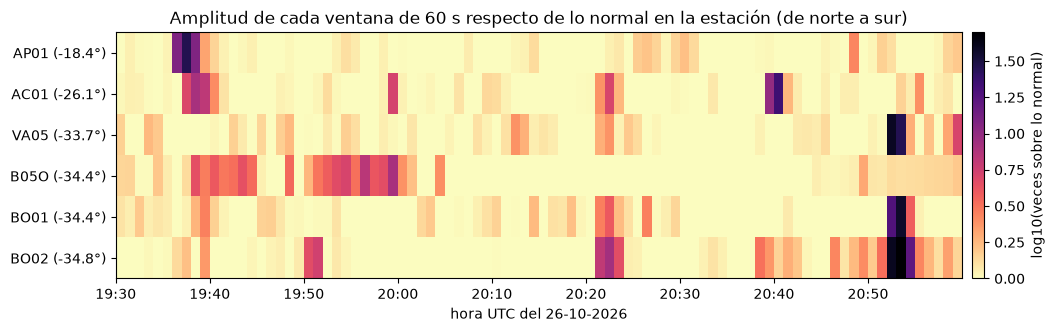

In [7]:
relacion = {}
for estacion, t in grupos.items():
    pico = np.abs(t["trazas"][:]).max(axis=1)
    # cada ventana empieza en el minuto UTC (± 1 muestra): se redondea al segundo para alinear estaciones
    inicios = pd.to_datetime(t["inicio_utc_ns"][:], utc=True).round("s")
    relacion[estacion] = pd.Series(pico / np.median(pico), index=inicios)
relacion = pd.DataFrame(relacion)[estaciones.sort_values("latitud", ascending=False).index.intersection(list(grupos))]

fig, ax = plt.subplots(figsize=(13, 3.2))
imagen = ax.imshow(np.log10(relacion.T.to_numpy(dtype=float)), aspect="auto", cmap="magma_r", vmin=0, vmax=1.7,
                   extent=(0, len(relacion), len(relacion.columns), 0), interpolation="nearest")
ax.set_yticks(np.arange(len(relacion.columns)) + 0.5, [f"{e} ({estaciones.latitud[e]:.1f}°)" for e in relacion.columns])
marcas = np.arange(0, len(relacion), 10)
ax.set_xticks(marcas, relacion.index[marcas].strftime("%H:%M"))
ax.set(xlabel=f"hora UTC del {relacion.index[0]:%d-%m-%Y}",
       title="Amplitud de cada ventana de 60 s respecto de lo normal en la estación (de norte a sur)")
fig.colorbar(imagen, ax=ax, label="log10(veces sobre lo normal)", pad=0.01)
plt.show()

**Detección por coincidencia** (la técnica clásica de las redes sismológicas): hay un posible sismo
cuando al menos dos estaciones superan 4 veces su nivel normal en el mismo minuto o en el siguiente.
Los minutos seguidos se juntan en una sola detección. Luego se cruza con el **catálogo USGS del
Lakehouse**: ¿hay un sismo cuyo origen esté entre 4 minutos antes y el fin del primer minuto?

In [8]:
UMBRAL, MIN_ESTACIONES = 4, 2

sobre = relacion >= UMBRAL
activas = (sobre | sobre.shift(-1, fill_value=False)).sum(axis=1)
candidatas = relacion.index[(activas >= MIN_ESTACIONES) & sobre.any(axis=1)]
episodios = []                                   # minutos candidatos seguidos = una detección
for minuto in candidatas:
    if episodios and minuto - episodios[-1][-1] <= pd.Timedelta(minutes=2):
        episodios[-1].append(minuto)
    else:
        episodios.append([minuto])

desde, hasta = relacion.index.min() - pd.Timedelta(minutes=5), relacion.index.max() + pd.Timedelta(minutes=1)
silver = cx.catalogo().load_table(cx.SILVER_TABLA)
catalogo = silver.scan(row_filter=f"tiempo_utc >= '{desde.isoformat()}' AND tiempo_utc < '{hasta.isoformat()}'",
                       selected_fields=("event_id", "tiempo_utc", "magnitud", "profundidad_km",
                                        "latitud", "longitud", "lugar")).to_pandas().sort_values("tiempo_utc")
print(f"Catálogo USGS entre {desde:%d-%m %H:%M} y {hasta:%H:%M} UTC: {len(catalogo)} sismos")

detecciones = []
for minutos in episodios:
    inicio = minutos[0]
    causa = catalogo[(catalogo.tiempo_utc >= inicio - pd.Timedelta(minutes=4))
                     & (catalogo.tiempo_utc < inicio + pd.Timedelta(minutes=1))]
    fila = {"desde": inicio, "minutos": len(minutos),
            "estaciones": ", ".join(relacion.columns[sobre.loc[minutos].any()]),
            "max_veces": round(float(relacion.loc[minutos].max().max()), 1)}
    if len(causa):
        e = causa.iloc[-1]
        fila |= {"sismo_catalogo": e.event_id, "magnitud": e.magnitud, "lugar": e.lugar}
    else:
        fila |= {"sismo_catalogo": "— no está en el catálogo USGS", "magnitud": None, "lugar": None}
    detecciones.append(fila)
pd.DataFrame(detecciones)

Catálogo USGS entre 26-10 19:25 y 21:00 UTC: 3 sismos


,desde,minutos,estaciones,max_veces,sismo_catalogo,magnitud,lugar
0,2026-10-26 19:36:00+00:00,4,"AP01, AC01, B05O",28.8,us7000ttbh,4.9,"100 km E of La Tirana, Chile"
1,2026-10-26 19:58:00+00:00,2,"AC01, B05O",8.1,— no está en el catálogo USGS,NaN,NaN
2,2026-10-26 20:21:00+00:00,2,"AC01, BO02",8.4,us7000ttbz,4.7,"7 km SE of Coquimbo, Chile"
3,2026-10-26 20:52:00+00:00,2,"VA05, BO01, BO02",68.9,us7000ttc8,4.6,"20 km NNW of La Ligua, Chile"


Las ventanas sin sismo en el catálogo pueden ser sismos menores que el USGS no publica (el CSN
registra muchos sismos chicos), o ruido local cerca de una estación (tránsito, obras). Las que sí
están confirman con el catálogo que la señal es un sismo.

## 6. Cómo luce la señal de un sismo

Para el sismo del catálogo que más resalta en las estaciones, se arma la señal continua de cada una
uniendo sus ventanas (Zarr baja solo los bloques de esos minutos) y se ordenan por distancia al
epicentro. Las líneas marcan cuándo debería llegar cada onda: la **P** (de compresión, la más
rápida, ~6,8 km/s) y la **S** (de corte, ~3,9 km/s, la que más sacude). Para cambiar de sismo,
pongan su `event_id` en `EVENTO`.

In [9]:
EVENTO = None
VP, VS = 6.8, 3.9   # km/s, velocidades medias de la corteza y el manto superior


def pasa_banda(x, hz, fmin=1.0, fmax=20.0):
    """Filtro pasa banda con la FFT: quita el microsismo oceánico (< 1 Hz) y el ruido de alta frecuencia."""
    espectro = np.fft.rfft(x - x.mean())
    frecuencias = np.fft.rfftfreq(len(x), 1 / hz)
    espectro[(frecuencias < fmin) | (frecuencias > fmax)] = 0
    return np.fft.irfft(espectro, len(x))


def senal(tensor, origen, antes_s=30, despues_s=240):
    """Une las ventanas que cubren [origen − antes_s, origen + despues_s].

    Devuelve (segundos desde el origen, muestras), con NaN donde el data lake no tiene la ventana.
    """
    inicios = pd.to_datetime(tensor["inicio_utc_ns"][:], utc=True).round("s")
    desde, hasta = origen - pd.Timedelta(seconds=antes_s), origen + pd.Timedelta(seconds=despues_s)
    filas = np.flatnonzero((inicios > desde - pd.Timedelta(seconds=60)) & (inicios < hasta))
    if not len(filas):
        return None, None
    primera, ultima = filas.min(), filas.max()
    bloque = tensor["trazas"][primera:ultima + 1]          # Zarr baja solo los bloques de esos minutos
    minutos = pd.date_range(inicios[primera], inicios[ultima], freq="60s")
    x = np.full((len(minutos), tensor["trazas"].shape[1]), np.nan, dtype="float32")
    for k, inicio in enumerate(inicios[primera:ultima + 1]):
        x[minutos.get_loc(inicio)] = bloque[k]
    t = (minutos[0] - origen).total_seconds() + np.arange(x.size) / tensor.attrs["muestras_por_seg"]
    dentro = (t >= -antes_s) & (t <= despues_s)
    return t[dentro], x.ravel()[dentro]


en_catalogo = [d for d in detecciones if d["magnitud"] is not None]
evento = catalogo.set_index("event_id").loc[EVENTO or max(en_catalogo, key=lambda d: d["max_veces"])["sismo_catalogo"]]
origen = evento.tiempo_utc
estaciones["distancia_km"] = cx.distancia_km(evento.latitud, evento.longitud, estaciones.latitud, estaciones.longitud)
estaciones["hipocentral_km"] = np.hypot(estaciones.distancia_km, evento.profundidad_km)
estaciones["llegada_p_s"] = estaciones.hipocentral_km / VP
estaciones["llegada_s_s"] = estaciones.hipocentral_km / VS
print(f"{evento.name}: M{evento.magnitud}, {origen:%d-%m-%Y %H:%M:%S} UTC, {evento.lugar}, "
      f"{evento.profundidad_km:.0f} km de profundidad")
estaciones.loc[list(grupos)].sort_values("distancia_km").round(1)

us7000ttc8: M4.6, 26-10-2026 20:52:11 UTC, 20 km NNW of La Ligua, Chile, 48 km de profundidad


,sitio,latitud,longitud,distancia_km,hipocentral_km,llegada_p_s,llegada_s_s
estacion,,,,,,,
VA05,Santo Domingo,-33.7,-71.6,155.8,162.9,24.0,41.8
BO01,Tunca,-34.4,-71.1,235.5,240.3,35.3,61.6
B05O,189 3ra Comisaria Pichilemu,-34.4,-72.0,243.2,247.9,36.5,63.6
BO02,Daracena,-34.8,-70.8,283.4,287.4,42.3,73.7
AC01,Pan de Azucar,-26.1,-70.6,685.4,687.0,101.0,176.2
AP01,Chacalluta,-18.4,-70.3,1549.7,1550.5,228.0,397.6


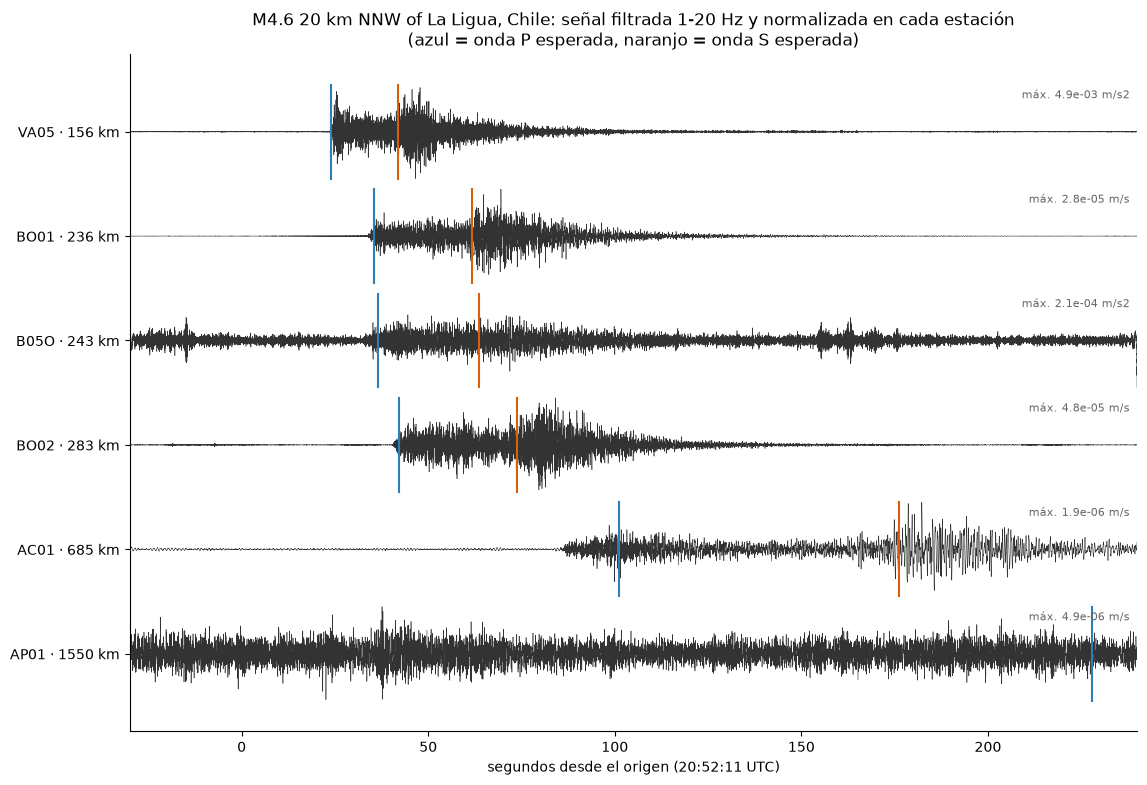

In [10]:
orden = estaciones.loc[list(grupos)].sort_values("distancia_km").index
fig, ax = plt.subplots(figsize=(13, 1.3 * len(orden) + 1))
for i, estacion in enumerate(orden):
    t, x = senal(grupos[estacion], origen)
    if t is None:
        continue
    hz, unidad = grupos[estacion].attrs["muestras_por_seg"], grupos[estacion].attrs["unidad"]
    x = np.where(np.isnan(x), np.nan, pasa_banda(np.nan_to_num(x), hz))
    pico = np.nanmax(np.abs(x))
    ax.plot(t, i + 0.45 * x / pico, color="#333", lw=0.4)
    ax.annotate(f"máx. {pico:.1e} {unidad}", (238, i - 0.32), ha="right", fontsize=8, color="#666")
    for llegada, color in ((estaciones.llegada_p_s[estacion], "#2c7fb8"), (estaciones.llegada_s_s[estacion], "#d95f0e")):
        ax.plot([llegada, llegada], [i - 0.45, i + 0.45], color=color, lw=1.5)
ax.set_yticks(range(len(orden)), [f"{e} · {estaciones.distancia_km[e]:.0f} km" for e in orden])
ax.invert_yaxis()
ax.set(xlim=(-30, 240), xlabel=f"segundos desde el origen ({origen:%H:%M:%S} UTC)",
       title=f"M{evento.magnitud} {evento.lugar}: señal filtrada 1-20 Hz y normalizada en cada estación\n"
             "(azul = onda P esperada, naranjo = onda S esperada)")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

En las estaciones a menos de 300 km la onda P llega casi justo donde se espera. Más lejos llega antes
de lo calculado: a esas distancias la onda viaja por el manto, más rápido (~8 km/s), y una velocidad
constante ya no alcanza. A 1.500 km un M4,6 casi no se distingue del ruido.

El espectrograma muestra la misma señal en tiempo y frecuencia, en la estación más cercana: el
sismo aparece como energía de 1 a 20 Hz que llega de golpe con la onda P, crece con la S y se apaga
en la coda. El ruido de fondo queda bajo 1 Hz (microsismo del oleaje).

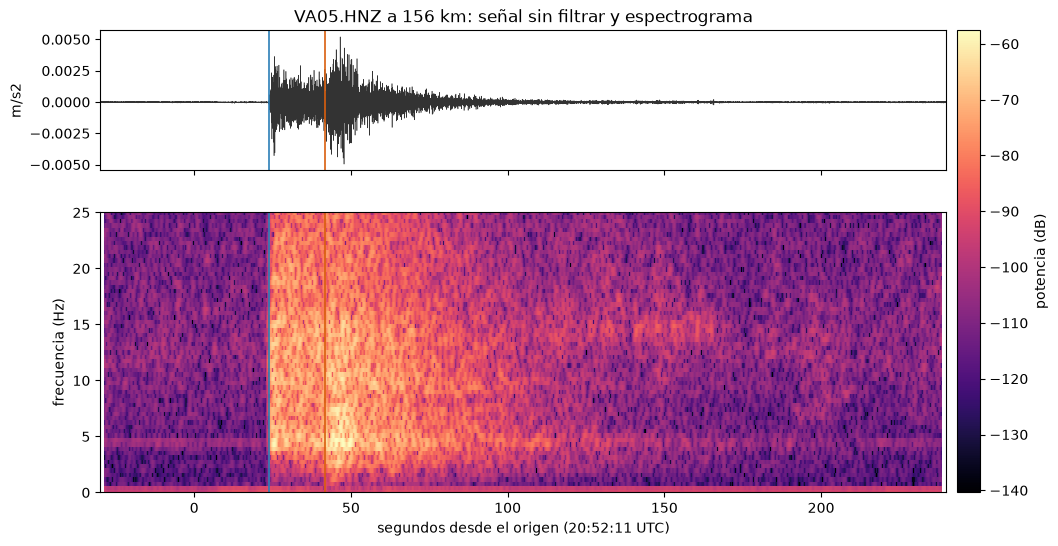

In [11]:
cercana = orden[0]
t, x = senal(grupos[cercana], origen)
hz = grupos[cercana].attrs["muestras_por_seg"]
x = np.nan_to_num(x)
potencia, frecuencias, tiempos = mlab.specgram(x, Fs=hz, NFFT=256, noverlap=224)
decibeles = 10 * np.log10(potencia + 1e-30)
fig, (arriba, abajo) = plt.subplots(2, 1, figsize=(13, 6), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
arriba.plot(t, x, color="#333", lw=0.4)
arriba.set(ylabel=grupos[cercana].attrs["unidad"], title=f"{cercana}.{grupos[cercana].attrs['canal']} "
           f"a {estaciones.distancia_km[cercana]:.0f} km: señal sin filtrar y espectrograma")
imagen = abajo.pcolormesh(t[0] + tiempos, frecuencias, decibeles, cmap="magma", shading="auto",
                          vmin=np.percentile(decibeles, 5), vmax=decibeles.max())
abajo.set(ylim=(0, 25), ylabel="frecuencia (Hz)", xlabel=f"segundos desde el origen ({origen:%H:%M:%S} UTC)",
          xlim=(-30, 240))
for llegada, color in ((estaciones.llegada_p_s[cercana], "#2c7fb8"), (estaciones.llegada_s_s[cercana], "#d95f0e")):
    for ax in (arriba, abajo):
        ax.axvline(llegada, color=color, lw=1.2)
fig.colorbar(imagen, ax=[arriba, abajo], label="potencia (dB)", pad=0.01)
plt.show()

**Cita de los datos:** Universidad de Chile (2013). Red Sismológica Nacional. International
Federation of Digital Seismograph Networks. https://doi.org/10.7914/SN/C1